In [1]:
from pathlib import Path
import json
import time
import gc
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    roc_curve, precision_recall_curve, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.calibration import calibration_curve

PROJECT_DIR = Path('C:/Case Study Trees/HiggsStudy')
PROCESSED_DIR = PROJECT_DIR / 'data/processed'
SPLIT_DIR = PROJECT_DIR / 'data/splits'
MODEL_DIR = PROJECT_DIR / 'artifacts/models'
INPUT_INFO_DIR = PROJECT_DIR / 'artifacts/input_info'
VALIDATION_DIR = PROJECT_DIR / 'results/validation'
TEST_DIR = PROJECT_DIR / 'results/test'
PREDICTION_DIR = PROJECT_DIR / 'results/predictions'
FIGURE_DIR = PROJECT_DIR / 'results/figures'
for folder in [TEST_DIR, PREDICTION_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_THREADS = 4
PREDICTION_BATCH_SIZE = 50_000
TIMING_BATCH_SIZE = 10_000
TIMING_REPEATS = 9
model_keys = ['xgb', 'lgb', 'cat']
model_names = {'xgb': 'XGBoost', 'lgb': 'LightGBM', 'cat': 'CatBoost'}
sns.set_theme(style='whitegrid')

versions = {'Python': platform.python_version(), 'Platform': platform.platform()}
for name in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'lightgbm', 'catboost', 'joblib']:
    versions[name] = importlib.metadata.version(name)
(TEST_DIR / 'evaluation_environment.json').write_text(json.dumps(versions, indent=2))
print('Three baseline models; no retraining or tuning in this notebook.')
print('CPU threads for prediction:', N_THREADS)

Three baseline models; no retraining or tuning in this notebook.
CPU threads for prediction: 4


# Load Validation Results

In [2]:
validation_results = pd.concat([
    pd.read_csv(VALIDATION_DIR / f'{key}_baseline_validation.csv')
    for key in model_keys
], ignore_index=True).sort_values('Validation_Log_Loss').reset_index(drop=True)
assert validation_results['Model'].is_unique
assert set(validation_results['Model']) == set(model_names.values())
validation_winner = validation_results.iloc[0]['Model']
validation_results.to_csv(VALIDATION_DIR / 'all_baseline_validation_comparison.csv', index=False)
display(validation_results.round(6))
print('Validation-selected model (lowest log loss):', validation_winner)

,Model,Version,Validation_Log_Loss,Validation_ROC_AUC,Validation_AP,Fit_Seconds,Validation_Prediction_Seconds,CPU_Threads
0,XGBoost,Baseline,0.526734,0.812138,0.827856,96.247407,0.378130,4
1,LightGBM,Baseline,0.530337,0.809071,0.825031,92.589218,1.533104,4
2,CatBoost,Baseline,0.542693,0.799855,0.816655,217.035138,0.207857,4


Validation-selected model (lowest log loss): XGBoost


# Load Validation and Test Arrays

In [3]:
X_valid = np.load(PROCESSED_DIR / 'X_valid.npy', mmap_mode='r')
y_valid = np.load(PROCESSED_DIR / 'y_valid.npy', mmap_mode='r')
X_test = np.load(PROCESSED_DIR / 'X_test.npy', mmap_mode='r')
y_test = np.load(PROCESSED_DIR / 'y_test.npy', mmap_mode='r')
valid_ids = np.load(SPLIT_DIR / 'valid_ids.npy', mmap_mode='r')
test_ids = np.load(SPLIT_DIR / 'test_ids.npy', mmap_mode='r')
with open(INPUT_INFO_DIR / 'higgs_input_info.json') as file:
    input_info = json.load(file)
assert X_valid.shape[1] == X_test.shape[1] == input_info['number_of_features']
assert len(X_valid) == len(y_valid) == len(valid_ids)
assert len(X_test) == len(y_test) == len(test_ids)
assert X_test.dtype == np.float32
assert set(np.unique(y_valid)) == {0, 1}
assert set(np.unique(y_test)) == {0, 1}
assert np.intersect1d(valid_ids, test_ids).size == 0
print('Validation:', X_valid.shape)
print('Test:', X_test.shape)
print('Test signal rate:', round(float(y_test.mean()), 4))
print('Target: 0 = background; 1 = signal')
print('Split:', input_info['split_method'])

Validation: (500000, 28)
Test: (500000, 28)
Test signal rate: 0.5299
Target: 0 = background; 1 = signal
Split: Stratified random split across converted records


# Prediction Helpers

In [4]:
def predict_probability(model, key, data):
    if key == 'cat':
        output = model.predict_proba(data, thread_count=N_THREADS)
    else:
        output = model.predict_proba(data)
    positive_column = list(model.classes_).index(1)
    return output[:, positive_column]


def predict_in_batches(model, key, data):
    probabilities = np.empty(len(data), dtype=np.float64)
    for start in range(0, len(data), PREDICTION_BATCH_SIZE):
        end = min(start + PREDICTION_BATCH_SIZE, len(data))
        batch = np.ascontiguousarray(data[start:end], dtype=np.float32)
        assert np.isfinite(batch).all(), 'Non-finite predictors found'
        probabilities[start:end] = predict_probability(model, key, batch)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    return probabilities


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()

print('Prediction helpers ready.')

Prediction helpers ready.


# Validate Models and Freeze Thresholds

In [5]:
thresholds = {}
threshold_rows = []
model_parameters = {}
for key in model_keys:
    print('Validation:', model_names[key], flush=True)
    model = joblib.load(MODEL_DIR / f'higgs_{key}_baseline.joblib')
    if key in ['xgb', 'lgb']:
        model.set_params(n_jobs=N_THREADS)
        expected_features = int(model.n_features_in_)
    else:
        expected_features = len(model.feature_names_)
    assert expected_features == X_valid.shape[1], 'Feature count mismatch'
    probabilities = predict_in_batches(model, key, X_valid)
    actual_loss = log_loss(y_valid, probabilities)
    saved_loss = validation_results.loc[
        validation_results['Model'] == model_names[key], 'Validation_Log_Loss'
    ].iloc[0]
    if not np.isclose(actual_loss, saved_loss, atol=1e-4, rtol=0):
        raise ValueError(f'{model_names[key]} validation log loss mismatch: '
                         f'{actual_loss:.6f} versus saved {saved_loss:.6f}')
    precision, recall, candidates = precision_recall_curve(y_valid, probabilities)
    scores = 2*precision[:-1]*recall[:-1] / np.maximum(precision[:-1]+recall[:-1], 1e-15)
    thresholds[key] = float(candidates[np.argmax(scores)])
    threshold_rows.append({'Model': model_names[key], 'Signal_F1_Threshold': thresholds[key],
                           'Validation_F1': float(scores.max()), 'Checked_Log_Loss': actual_loss})
    model_parameters[key] = model.get_params()
    pd.DataFrame({'ROW_ID': valid_ids, 'TARGET': y_valid,
                  'Signal_Probability': probabilities}).to_csv(
        PREDICTION_DIR / f'higgs_{key}_validation.csv', index=False)
    del model, probabilities
    gc.collect()
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(VALIDATION_DIR / 'frozen_baseline_thresholds.csv', index=False)
(TEST_DIR / 'frozen_evaluation_settings.json').write_text(json.dumps({
    'Validation_Selected_Model': validation_winner,
    'Primary_Metric': 'Log_Loss', 'Threshold_Objective': 'Validation signal F1',
    'Thresholds': thresholds, 'CPU_Threads': N_THREADS,
    'Timing_Batch_Size': TIMING_BATCH_SIZE, 'Timing_Repeats': TIMING_REPEATS,
    'Model_Parameters': model_parameters
}, indent=2, default=str))
display(threshold_table.round(6))
print('Thresholds and configurations frozen before test evaluation.')

Validation: XGBoost
Validation: LightGBM
Validation: CatBoost


,Model,Signal_F1_Threshold,Validation_F1,Checked_Log_Loss
0,XGBoost,0.383715,0.764895,0.526734
1,LightGBM,0.385820,0.762955,0.530337
2,CatBoost,0.401024,0.756875,0.542693


Thresholds and configurations frozen before test evaluation.


# Test Metrics and Repeated Inference Timing

In [6]:
timing_batch = np.array(X_test[:min(TIMING_BATCH_SIZE, len(X_test))],
                        dtype=np.float32, order='C', copy=True)
test_predictions = {}
metric_rows = []
timing_rows = []
for key in model_keys:
    print('Test evaluation:', model_names[key], flush=True)
    model = joblib.load(MODEL_DIR / f'higgs_{key}_baseline.joblib')
    if key in ['xgb', 'lgb']:
        model.set_params(n_jobs=N_THREADS)

    # Warm up on identical resident inputs.
    for _ in range(2):
        predict_probability(model, key, timing_batch)
    times = []
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        predict_probability(model, key, timing_batch)
        times.append(time.perf_counter()-start)
    scale = 1000 / len(timing_batch)
    timing_rows.append({
        'Model': model_names[key], 'Batch_Rows': len(timing_batch),
        'Repeats': TIMING_REPEATS, 'CPU_Threads': N_THREADS,
        'Inference_Seconds_Per_1000': float(np.median(times)*scale),
        'Inference_Milliseconds_Per_1000': float(np.median(times)*scale*1000),
        'Inference_P25_ms_Per_1000': float(np.percentile(times, 25)*scale*1000),
        'Inference_P75_ms_Per_1000': float(np.percentile(times, 75)*scale*1000),
        'Batch_Median_Seconds': float(np.median(times)),
        'Model_File_MiB': (MODEL_DIR / f'higgs_{key}_baseline.joblib').stat().st_size/1024**2
    })

    start = time.perf_counter()
    probabilities = predict_in_batches(model, key, X_test)
    full_test_seconds = time.perf_counter()-start
    predictions = (probabilities >= thresholds[key]).astype(np.uint8)
    test_predictions[key] = probabilities
    metric_rows.append({
        'Model': model_names[key], 'Version': 'Baseline',
        'Test_Log_Loss': log_loss(y_test, probabilities),
        'Test_ROC_AUC': roc_auc_score(y_test, probabilities),
        'Test_AP': average_precision_score(y_test, probabilities),
        'Test_Brier': brier_score_loss(y_test, probabilities),
        'Test_Accuracy': accuracy_score(y_test, predictions),
        'Test_Balanced_Accuracy': balanced_accuracy_score(y_test, predictions),
        'Test_Precision': precision_score(y_test, predictions, zero_division=0),
        'Test_Recall': recall_score(y_test, predictions, zero_division=0),
        'Test_F1': f1_score(y_test, predictions, zero_division=0),
        'Threshold': thresholds[key], 'Full_Test_Prediction_Seconds': full_test_seconds
    })
    pd.DataFrame({'ROW_ID': test_ids, 'TARGET': y_test,
                  'Signal_Probability': probabilities, 'Prediction': predictions}).to_csv(
        PREDICTION_DIR / f'higgs_{key}_test.csv', index=False)
    del model, predictions
    gc.collect()

test_results = pd.DataFrame(metric_rows).sort_values('Test_Log_Loss').reset_index(drop=True)
timing_results = pd.DataFrame(timing_rows)
test_results.to_csv(TEST_DIR / 'higgs_baseline_test_metrics.csv', index=False)
timing_results.to_csv(TEST_DIR / 'higgs_baseline_inference_times.csv', index=False)
display(test_results.round(6))
display(timing_results.round(6))
print('AP means average precision, not trapezoidal PR-AUC.')
print('Inference benchmark: warm model calls on a resident NumPy batch; model loading and disk reads excluded.')
print('Full-test prediction time also includes batching, validation checks and possible disk paging.')
print('Per-1,000-row times are scaled batch measurements, not single-request latency.')

Test evaluation: XGBoost
Test evaluation: LightGBM
Test evaluation: CatBoost


,Model,Version,Test_Log_Loss,Test_ROC_AUC,Test_AP,Test_Brier,Test_Accuracy,Test_Balanced_Accuracy,Test_Precision,Test_Recall,Test_F1,Threshold,Full_Test_Prediction_Seconds
0,XGBoost,Baseline,0.525608,0.813465,0.828584,0.176262,0.714796,0.704476,0.678654,0.877070,0.765209,0.383715,0.506216
1,LightGBM,Baseline,0.529573,0.810011,0.825557,0.177870,0.712048,0.701610,0.676182,0.876187,0.763300,0.385820,1.485034
2,CatBoost,Baseline,0.542077,0.800778,0.817005,0.182679,0.704300,0.693782,0.670325,0.869691,0.757104,0.401024,0.154285


,Model,Batch_Rows,Repeats,CPU_Threads,Inference_Seconds_Per_1000,Inference_Milliseconds_Per_1000,Inference_P25_ms_Per_1000,Inference_P75_ms_Per_1000,Batch_Median_Seconds,Model_File_MiB
0,XGBoost,10000,9,4,0.000925,0.92487,0.86174,0.97510,0.009249,0.478596
1,LightGBM,10000,9,4,0.003154,3.15427,3.12900,3.20484,0.031543,0.351980
2,CatBoost,10000,9,4,0.000432,0.43231,0.42496,0.47132,0.004323,0.115553


AP means average precision, not trapezoidal PR-AUC.
Inference benchmark: warm model calls on a resident NumPy batch; model loading and disk reads excluded.
Full-test prediction time also includes batching, validation checks and possible disk paging.
Per-1,000-row times are scaled batch measurements, not single-request latency.


# Final Comparison and Winners

In [7]:
comparison = test_results.merge(timing_results, on='Model', validate='one_to_one')
comparison = comparison.merge(
    validation_results[['Model', 'Fit_Seconds', 'CPU_Threads']].rename(
        columns={'CPU_Threads': 'Training_CPU_Threads'}),
    on='Model', validate='one_to_one'
)
comparison.to_csv(TEST_DIR / 'higgs_baseline_final_comparison.csv', index=False)
winners = pd.DataFrame([
    {'Category': 'Validation-selected model', 'Winner': validation_winner},
    {'Category': 'Lowest observed test log loss', 'Winner': comparison.loc[comparison['Test_Log_Loss'].idxmin(), 'Model']},
    {'Category': 'Highest observed test ROC-AUC', 'Winner': comparison.loc[comparison['Test_ROC_AUC'].idxmax(), 'Model']},
    {'Category': 'Highest observed test AP', 'Winner': comparison.loc[comparison['Test_AP'].idxmax(), 'Model']},
    {'Category': 'Fastest recorded final fit', 'Winner': comparison.loc[comparison['Fit_Seconds'].idxmin(), 'Model']},
    {'Category': 'Fastest median batch inference', 'Winner': comparison.loc[comparison['Inference_Seconds_Per_1000'].idxmin(), 'Model']}
])
winners.to_csv(TEST_DIR / 'higgs_baseline_winners.csv', index=False)
display(comparison[['Model', 'Test_Log_Loss', 'Test_ROC_AUC', 'Test_AP',
                    'Fit_Seconds', 'Inference_Milliseconds_Per_1000']].round(6))
display(winners)
print('Fit times are original single training runs, not repeated benchmark estimates.')
print('CPU_Threads records CPU allocation, not proof of CPU-only training. Label GPU runs separately if used.')
print('Results apply to these configurations and this split; no test-driven retuning.')

,Model,Test_Log_Loss,Test_ROC_AUC,Test_AP,Fit_Seconds,Inference_Milliseconds_Per_1000
0,XGBoost,0.525608,0.813465,0.828584,96.247407,0.92487
1,LightGBM,0.529573,0.810011,0.825557,92.589218,3.15427
2,CatBoost,0.542077,0.800778,0.817005,217.035138,0.43231


,Category,Winner
0,Validation-selected model,XGBoost
1,Lowest observed test log loss,XGBoost
2,Highest observed test ROC-AUC,XGBoost
3,Highest observed test AP,XGBoost
4,Fastest recorded final fit,LightGBM
5,Fastest median batch inference,CatBoost


Fit times are original single training runs, not repeated benchmark estimates.
CPU_Threads records CPU allocation, not proof of CPU-only training. Label GPU runs separately if used.
Results apply to these configurations and this split; no test-driven retuning.


# Test Metric Comparison

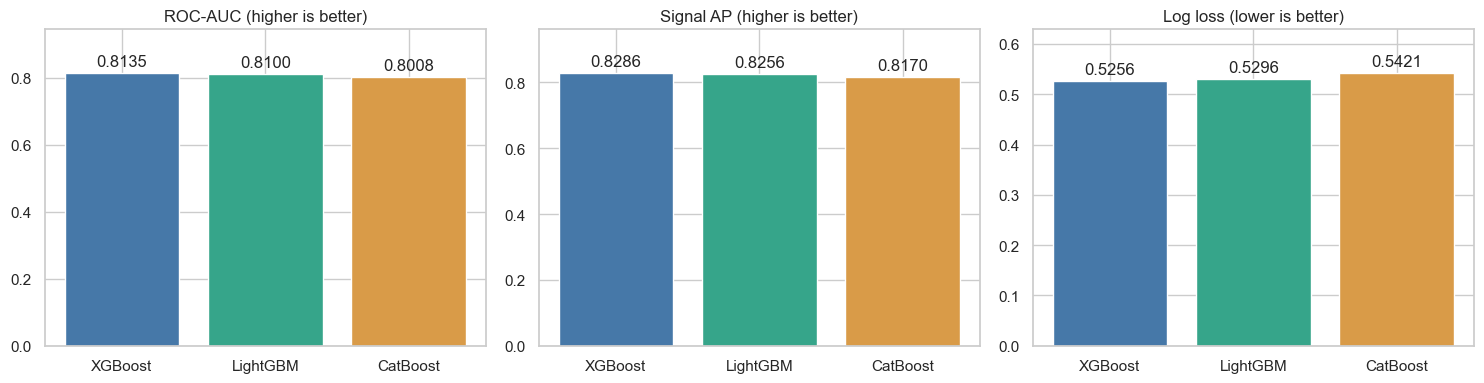

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(axes,
    ['Test_ROC_AUC', 'Test_AP', 'Test_Log_Loss'],
    ['ROC-AUC (higher is better)', 'Signal AP (higher is better)', 'Log loss (lower is better)']):
    bars = ax.bar(comparison['Model'], comparison[column], color=['#4678a8', '#36a58a', '#d99b48'])
    ax.bar_label(bars, fmt='%.4f', padding=3)
    ax.set_title(title)
    ax.set_ylim(0, comparison[column].max()*1.16)
save_plot('higgs_01_test_metrics.png')

# ROC and Precision–Recall Curves

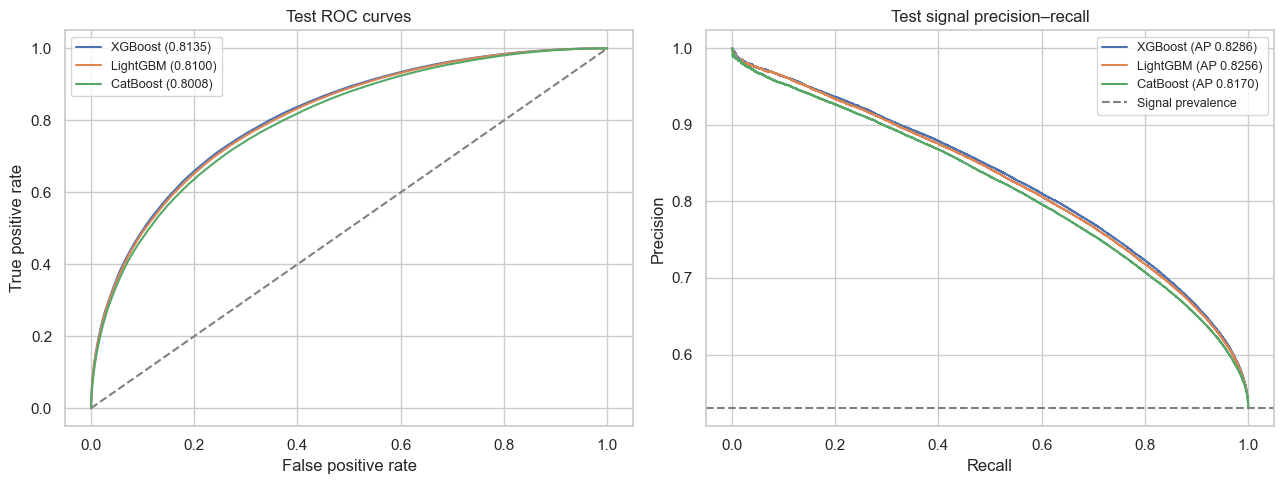

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for key in model_keys:
    probabilities = test_predictions[key]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    axes[0].plot(fpr, tpr, label=f'{model_names[key]} ({roc_auc_score(y_test, probabilities):.4f})')
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    axes[1].plot(recall, precision, label=f'{model_names[key]} (AP {average_precision_score(y_test, probabilities):.4f})')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set(title='Test ROC curves', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(float(y_test.mean()), linestyle='--', color='grey', label='Signal prevalence')
axes[1].set(title='Test signal precision–recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=9)
save_plot('higgs_02_roc_precision_recall.png')

# Training and Inference Times

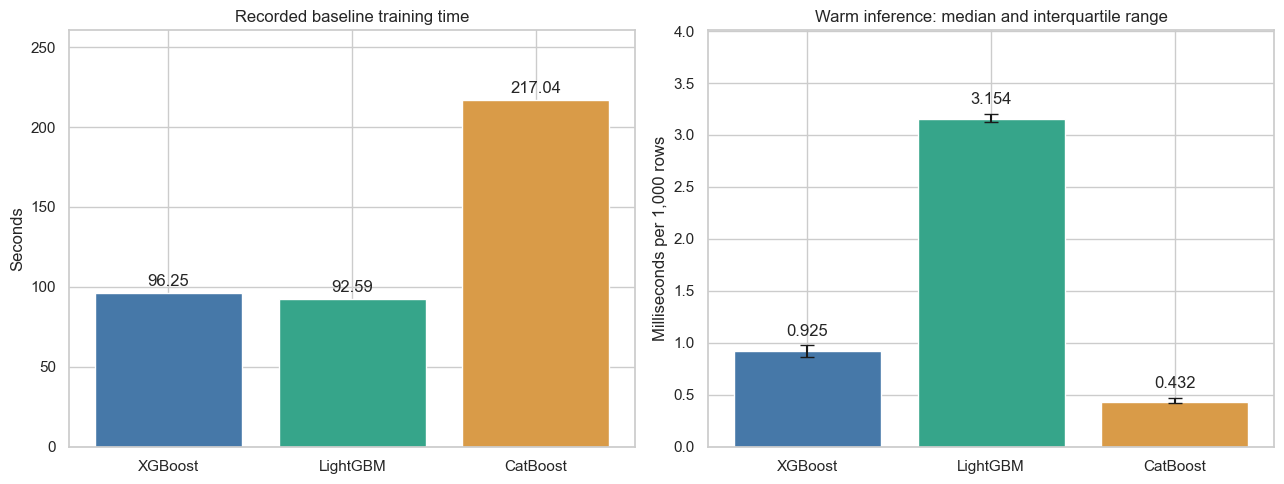

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(comparison['Model'], comparison['Fit_Seconds'], color=['#4678a8', '#36a58a', '#d99b48'])
axes[0].bar_label(bars, fmt='%.2f', padding=3)
axes[0].set(title='Recorded baseline training time', ylabel='Seconds')
axes[0].set_ylim(0, comparison['Fit_Seconds'].max()*1.2)
values = comparison['Inference_Milliseconds_Per_1000'].to_numpy()
errors = np.vstack([
    values-comparison['Inference_P25_ms_Per_1000'].to_numpy(),
    comparison['Inference_P75_ms_Per_1000'].to_numpy()-values
])
bars = axes[1].bar(comparison['Model'], values, yerr=errors, capsize=5,
                   color=['#4678a8', '#36a58a', '#d99b48'])
axes[1].bar_label(bars, fmt='%.3f', padding=5)
axes[1].set(title='Warm inference: median and interquartile range', ylabel='Milliseconds per 1,000 rows')
axes[1].set_ylim(0, comparison['Inference_P75_ms_Per_1000'].max()*1.25)
save_plot('higgs_03_training_inference.png')

# Confusion Matrices

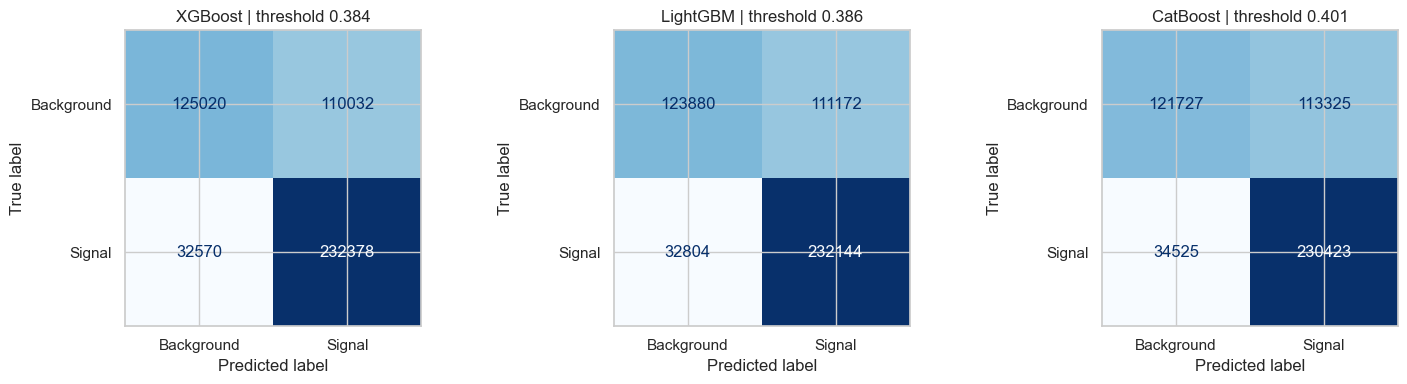

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key in zip(axes, model_keys):
    predictions = (test_predictions[key] >= thresholds[key]).astype(np.uint8)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['Background', 'Signal']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{model_names[key]} | threshold {thresholds[key]:.3f}')
save_plot('higgs_04_confusion_matrices.png')

# Calibration

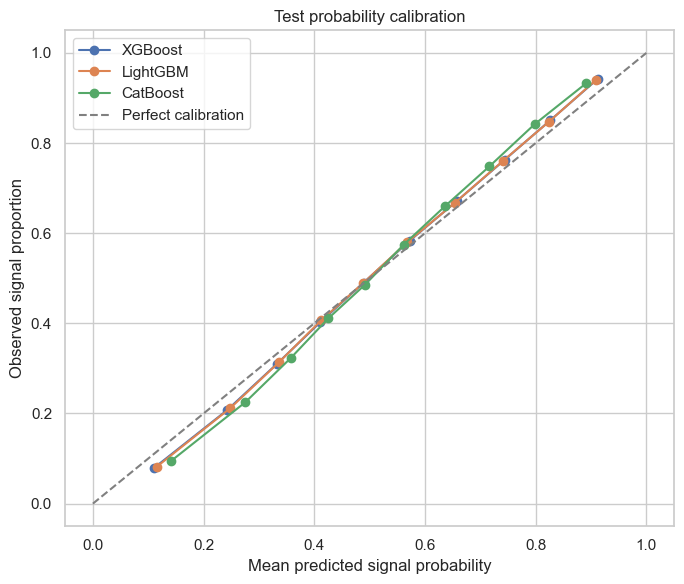

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
for key in model_keys:
    observed, predicted = calibration_curve(y_test, test_predictions[key], n_bins=10, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=model_names[key])
ax.plot([0, 1], [0, 1], '--', color='grey', label='Perfect calibration')
ax.set(title='Test probability calibration', xlabel='Mean predicted signal probability',
       ylabel='Observed signal proportion')
ax.legend()
save_plot('higgs_05_calibration.png')

# Summary

In [13]:
display(winners)
display(comparison[['Model', 'Test_Log_Loss', 'Test_ROC_AUC', 'Test_AP',
                    'Fit_Seconds', 'Inference_Milliseconds_Per_1000']].round(6))
print('Comparing three fixed 100-tree boosting configurations, not tuned models.')
print('Equal tree counts do not mean equal tree structures or computational work.')
print('Small metric or timing gaps should not be treated as conclusive algorithm-wide advantages.')
print('Results:', TEST_DIR)
print('Graphs:', FIGURE_DIR)

,Category,Winner
0,Validation-selected model,XGBoost
1,Lowest observed test log loss,XGBoost
2,Highest observed test ROC-AUC,XGBoost
3,Highest observed test AP,XGBoost
4,Fastest recorded final fit,LightGBM
5,Fastest median batch inference,CatBoost


,Model,Test_Log_Loss,Test_ROC_AUC,Test_AP,Fit_Seconds,Inference_Milliseconds_Per_1000
0,XGBoost,0.525608,0.813465,0.828584,96.247407,0.92487
1,LightGBM,0.529573,0.810011,0.825557,92.589218,3.15427
2,CatBoost,0.542077,0.800778,0.817005,217.035138,0.43231


Comparing three fixed 100-tree boosting configurations, not tuned models.
Equal tree counts do not mean equal tree structures or computational work.
Small metric or timing gaps should not be treated as conclusive algorithm-wide advantages.
Results: C:\Case Study Trees\HiggsStudy\results\test
Graphs: C:\Case Study Trees\HiggsStudy\results\figures
